# 54 — Autoregressive models and exact likelihood

An autoregressive model uses the probability chain rule to replace one complicated joint distribution with a sequence of conditional distributions. In this notebook we will calculate those probabilities explicitly, train a small causal model, evaluate exact negative log-likelihood, and generate tiny binary images one pixel at a time.

The main questions are:

- How does the probability chain rule define a normalized joint distribution?
- Why is teacher-forced training parallel but generation sequential?
- How does next-token cross-entropy become exact negative log-likelihood?
- What does a raster ordering add—and remove—when an image becomes a sequence?

In [1]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE

device(type='cpu')

## 1. From a joint probability to conditional factors

For a sequence $x=(x_1,\ldots,x_T)$, the probability chain rule gives

$$
p(x)=p(x_1)\prod_{t=2}^{T}p(x_t\mid x_1,\ldots,x_{t-1}).
$$

The factor at position $t$ is allowed to use only earlier values. Multiplying all factors assigns a probability to the complete sequence. If every conditional factor is normalized, the resulting joint distribution is normalized too.

### Exercise 1 — Calculate one sequence probability

For the binary sequence `(1, 0, 1)`, use the supplied conditional probabilities to calculate

$$
p(1,0,1)=p(x_1=1)p(x_2=0\mid x_1=1)p(x_3=1\mid x_1=1,x_2=0).
$$

In [2]:
p_x1_is_1 = 0.60
p_x2_is_0_given_x1_is_1 = 0.25
p_x3_is_1_given_10 = 0.80

# multiply the three appropriate conditional factors.
sequence_probability = p_x1_is_1 * p_x2_is_0_given_x1_is_1 * p_x3_is_1_given_10

assert sequence_probability is not None
assert math.isclose(sequence_probability, 0.12)
sequence_probability

0.12

The multiplication is not three independent predictions. The second probability is conditioned on the first observed value, and the third is conditioned on both earlier values. That dependence is what lets the product represent structure in the sequence.

## 2. Exact negative log-likelihood

Products of many probabilities become extremely small. Taking a logarithm turns the product into a sum:

$$
-\log p(x)=-\sum_{t=1}^{T}\log p(x_t\mid x_{1:t-1}).
$$

This is exact negative log-likelihood (NLL), not an approximation: the model explicitly provides every normalized conditional factor.

### Exercise 2 — Gather target probabilities

`probabilities[n, t, v]` stores the predicted probability of value `v` at position `t`. Use the integer targets to gather the probability assigned to the value that actually occurred, then sum its negative logarithm for each sequence.

In [3]:
def sequence_nll_from_probabilities(probabilities, targets):
    if probabilities.ndim != 3:
        raise ValueError("probabilities must have shape (N, T, V)")
    if targets.shape != probabilities.shape[:2]:
        raise ValueError("targets must have shape (N, T)")

    # gather one target probability at every (batch, time) position.
    target_probabilities = probabilities[
        torch.arange(probabilities.size(0)).unsqueeze(1),
        torch.arange(probabilities.size(1)),
        targets,
    ]
    # return one summed negative log-likelihood per sequence.
    return -torch.log(target_probabilities).sum(dim=1)


toy_probabilities = torch.tensor([
    [[0.40, 0.65], [0.25, 0.75], [0.20, 0.80]],
    [[0.70, 0.30], [0.60, 0.40], [0.90, 0.10]],
])
toy_targets = torch.tensor([[1, 0, 1], [0, 1, 0]])
toy_nll = sequence_nll_from_probabilities(toy_probabilities, toy_targets)
expected_nll = -torch.log(torch.tensor([0.65 * 0.25 * 0.80, 0.70 * 0.40 * 0.90]))
torch.testing.assert_close(toy_nll, expected_nll)
toy_nll

tensor([2.0402, 1.3783])

#### How the three index arrays work

`toy_probabilities` has shape `(N, T, V) = (2, 3, 2)`, so `probabilities[n, t, v]` means: sequence `n`, position `t`, and vocabulary class `v`. We need one probability at every `(n, t)` position: the probability assigned to the target class stored in `targets[n, t]`.

The batch indices have shape `(N, 1)` and look like `[[0], [1]]`. The time indices have shape `(1, T)` and look like `[[0, 1, 2]]`. Broadcasting combines them into an `(N, T)` coordinate grid:

```text
batch coordinates:  [[0, 0, 0],    time coordinates:  [[0, 1, 2],
                     [1, 1, 1]]                        [0, 1, 2]]
```

Using only these first two arrays, `probabilities[batch_indices, time_indices]`, selects every `(n, t)` entry but leaves the vocabulary axis unselected, so its shape is still `(N, T, V)`. The third array, `targets` with shape `(N, T)`, supplies the vocabulary coordinate for each position. The complete indexing expression therefore returns shape `(N, T)`.

For this example, the selected coordinate triplets are `(0, 0, 1)`, `(0, 1, 0)`, `(0, 2, 1)`, `(1, 0, 0)`, `(1, 1, 1)`, and `(1, 2, 0)`. Their probabilities are `0.65, 0.25, 0.80, 0.70, 0.40, 0.90`.

The `unsqueeze` calls are important: raw shapes `(N,)` and `(T,)` cannot broadcast when `N != T`. Shapes `(N, 1)` and `(1, T)` can broadcast to their shared grid `(N, T)`.

In [4]:
# Shape trace: select one value from the V axis for every (N, T) position.
N, T, V = toy_probabilities.shape

# Advanced indexing: (N, 1), (1, T), and (N, T) broadcast to (N, T).
batch_indices = torch.arange(N, device=toy_probabilities.device).unsqueeze(1)
time_indices = torch.arange(T, device=toy_probabilities.device).unsqueeze(0)
selected_with_indexing = toy_probabilities[
    batch_indices,
    time_indices,
    toy_targets,
]

# gather alternative: add a size-1 index axis corresponding to V.
gather_indices = toy_targets.unsqueeze(-1)
selected_with_gather = toy_probabilities.gather(
    dim=2,
    index=gather_indices,
).squeeze(-1)

# log keeps (N, T); summing over T leaves one NLL for each sequence.
negative_log_probabilities = -selected_with_gather.log()
nll_per_sequence = negative_log_probabilities.sum(dim=1)

torch.testing.assert_close(selected_with_indexing, selected_with_gather)
print("probabilities:            ", toy_probabilities.shape, "(N, T, V)")
print("targets:                  ", toy_targets.shape, "(N, T)")
print("batch indices:            ", batch_indices.shape)
print("time indices:             ", time_indices.shape)
print("gather indices:           ", gather_indices.shape, "(N, T, 1)")
print("selected probabilities:   ", selected_with_gather.shape, "(N, T)")
print("NLL per sequence:         ", nll_per_sequence.shape, "(N,)")
print("\nselected probabilities:\n", selected_with_gather)
print("\nNLL per sequence:\n", nll_per_sequence)

probabilities:             torch.Size([2, 3, 2]) (N, T, V)
targets:                   torch.Size([2, 3]) (N, T)
batch indices:             torch.Size([2, 1])
time indices:              torch.Size([1, 3])
gather indices:            torch.Size([2, 3, 1]) (N, T, 1)
selected probabilities:    torch.Size([2, 3]) (N, T)
NLL per sequence:          torch.Size([2]) (N,)

selected probabilities:
 tensor([[0.6500, 0.2500, 0.8000],
        [0.7000, 0.4000, 0.9000]])

NLL per sequence:
 tensor([2.0402, 1.3783])


In Exercise 2, we started with probabilities, selected the probability assigned to each target token, applied `-log`, and summed the results across the sequence. A neural network instead produces raw class scores called **logits**, with one score for every vocabulary item at every sequence position. We could apply `softmax`, select the target probabilities, and then take `-log` manually, but very small probabilities could round to zero and make `log(0)` undefined. PyTorch's `cross_entropy` performs the equivalent `log_softmax` and target-selection operations together in a numerically stable way. It returns one negative log-likelihood value for each token; summing those token losses across time gives the NLL of the complete sequence, while averaging them would give the average NLL per token.

## 3. A structured binary-image dataset

We will generate `8×8` images containing horizontal bars, vertical bars, crosses, or rectangular borders. A small amount of random pixel noise prevents the training set from containing only exact templates. No class labels are given to the model.

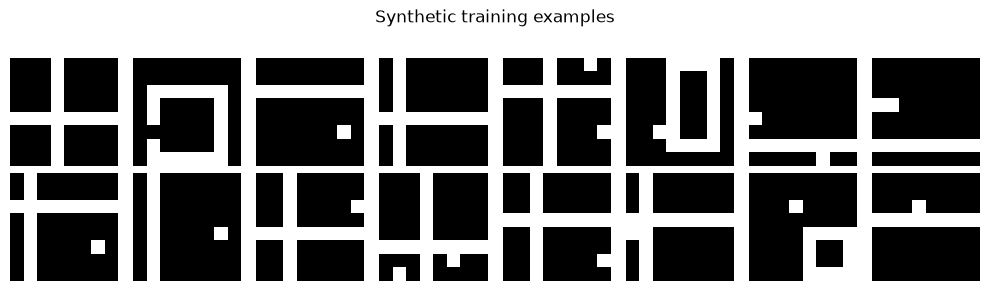

In [5]:
def make_binary_shape_images(number_images, image_size=8, noise_probability=0.02, seed=0):
    generator = torch.Generator().manual_seed(seed)
    images = torch.zeros(number_images, image_size, image_size, dtype=torch.long)
    kinds = torch.randint(0, 4, (number_images,), generator=generator)

    for index, kind in enumerate(kinds.tolist()):
        row = int(torch.randint(1, image_size - 1, (), generator=generator))
        column = int(torch.randint(1, image_size - 1, (), generator=generator))
        if kind == 0:
            images[index, row, :] = 1
        elif kind == 1:
            images[index, :, column] = 1
        elif kind == 2:
            images[index, row, :] = 1
            images[index, :, column] = 1
        else:
            top = int(torch.randint(0, image_size - 3, (), generator=generator))
            left = int(torch.randint(0, image_size - 3, (), generator=generator))
            bottom = int(torch.randint(top + 2, image_size, (), generator=generator))
            right = int(torch.randint(left + 2, image_size, (), generator=generator))
            images[index, top, left : right + 1] = 1
            images[index, bottom, left : right + 1] = 1
            images[index, top : bottom + 1, left] = 1
            images[index, top : bottom + 1, right] = 1

    noise = torch.rand(number_images, image_size, image_size, generator=generator)
    return torch.where(noise < noise_probability, 1 - images, images)


train_images = make_binary_shape_images(4000, seed=SEED)
evaluation_images = make_binary_shape_images(1000, seed=SEED + 1)

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for axis, image in zip(axes.flat, train_images[:16]):
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    axis.axis("off")
plt.suptitle("Synthetic training examples")
plt.tight_layout()
plt.show()

## 4. Images become raster-ordered sequences

A raster scan lists pixels from left to right, then proceeds to the next row. An `8×8` image therefore becomes a sequence of 64 binary values. This order is a modeling choice, not an intrinsic property of an image.

### Exercise 3 — Flatten and restore images

Implement the two shape transformations and verify an exact round trip.

In [6]:
def images_to_sequences(images):
    if images.ndim != 3:
        raise ValueError("images must have shape (N, H, W)")
    # preserve the batch axis and merge the two spatial axes.
    return images.reshape(images.shape[0], -1)


def sequences_to_images(sequences, image_size):
    if sequences.ndim != 2:
        raise ValueError("sequences must have shape (N, T)")
    if sequences.shape[1] != image_size * image_size:
        raise ValueError("sequence length does not match image_size squared")
    # split the sequence axis into height and width.
    return sequences.reshape(sequences.shape[0], image_size, image_size)


train_sequences = images_to_sequences(train_images)
evaluation_sequences = images_to_sequences(evaluation_images)
assert train_sequences.shape == (4000, 64)
torch.testing.assert_close(sequences_to_images(train_sequences, 8), train_images)

## 5. Shift inputs to prevent seeing the target

To predict target $x_t$, the model input at that position must contain only earlier information. We prepend a special beginning-of-sequence token and remove the final pixel:

```text
target:  x1  x2  x3  x4
input:  BOS  x1  x2  x3
```

If we passed the unshifted target as input, the model could copy the value it was asked to predict.

### Exercise 4 — Create teacher-forcing inputs

In [7]:
BOS_TOKEN = 2


def make_autoregressive_inputs(targets, bos_token=BOS_TOKEN):
    if targets.ndim != 2:
        raise ValueError("targets must have shape (N, T)")
    # create a (N, 1) BOS column with matching dtype and device.
    beginning = torch.full((targets.shape[0], 1), bos_token, dtype=targets.dtype, device=targets.device)
    # prepend BOS and keep every target except the final one.
    return torch.cat([beginning, targets[:, :-1]], dim=1)


toy_targets = torch.tensor([[1, 0, 1, 1], [0, 0, 1, 0]])
toy_inputs = make_autoregressive_inputs(toy_targets)
expected_inputs = torch.tensor([[2, 1, 0, 1], [2, 0, 0, 1]])
torch.testing.assert_close(toy_inputs, expected_inputs)

## 6. A causal recurrent model

The embedding converts the three possible input tokens—zero, one, and BOS—into vectors. The GRU processes them from left to right, so output position $t$ cannot depend on later inputs. Although its direct input at that step is only the immediately preceding pixel, its hidden state carries a compressed summary of all earlier pixels. For example, the prediction of $x_4$ directly receives $x_3$, while the hidden state can also contain information from $x_1$ and $x_2$. The model therefore represents $p(x_4 \mid x_1,x_2,x_3)$ rather than only $p(x_4 \mid x_3)$. A final linear layer produces two logits for the next binary pixel.

The GRU is used here because its causal direction is explicit and sampling can reuse its hidden state. A causally masked Transformer could represent the same factorization.

In [8]:
class BinaryImageAutoregressiveModel(nn.Module):
    def __init__(self, embedding_dim=16, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(3, embedding_dim)
        self.gru = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, 2)

    def forward(self, token_ids, hidden=None):
        embedded = self.embedding(token_ids)
        features, hidden = self.gru(embedded, hidden)
        return self.output(features), hidden


torch.manual_seed(SEED)
sample_model = BinaryImageAutoregressiveModel()
sample_logits, sample_hidden = sample_model(toy_inputs)
assert sample_logits.shape == (2, 4, 2)
assert sample_hidden.shape == (1, 2, 64)

### Exercise 5 — Cross-entropy and causal verification

Flatten batch and time together so cross-entropy sees `(N*T, 2)` logits and `(N*T,)` targets. Then verify causality: changing an input token may change predictions at that position and later positions, but it must not change earlier logits.

In [9]:
def autoregressive_cross_entropy(logits, targets, reduction="mean"):
    if logits.shape[:2] != targets.shape or logits.shape[-1] != 2:
        raise ValueError("expected logits (N, T, 2) and targets (N, T)")
    # merge N and T for both tensors, then calculate cross-entropy.
    return F.cross_entropy(logits.reshape(-1, 2), targets.reshape(-1), reduction=reduction)


toy_loss = autoregressive_cross_entropy(sample_logits, toy_targets)
expected_loss = F.cross_entropy(sample_logits.reshape(-1, 2), toy_targets.reshape(-1))
torch.testing.assert_close(toy_loss, expected_loss)

changed_inputs = toy_inputs.clone()
changed_inputs[:, 2] = 1 - changed_inputs[:, 2]
changed_logits, _ = sample_model(changed_inputs)
# Positions 0 and 1 occur before the changed input at position 2.
torch.testing.assert_close(sample_logits[:, :2], changed_logits[:, :2])
assert not torch.allclose(sample_logits[:, 2:], changed_logits[:, 2:])

Notice that the output at position `t` predicts target `x_t` after consuming the shifted input at position `t`. The change at input position 2 can therefore affect output position 2, but it cannot travel backward to outputs 0 or 1.

## 7. Train with teacher forcing

Section 6 defined the causal model architecture; this section describes how we train that same model. For a target sequence `[x1, x2, x3, x4]`, teacher forcing supplies the shifted input `[BOS, x1, x2, x3]`. The model output at each position is compared with the corresponding original target `[x1, x2, x3, x4]`. It therefore learns to predict each pixel from the true pixels that precede it.

Because every earlier ground-truth pixel is already available during training, the complete shifted sequence can pass through the GRU in one call and all 64 next-pixel losses can be calculated together. During generation, however, the future ground-truth pixels are unavailable: the model must predict one pixel, feed that prediction back as its next input, and continue step by step. This difference can create **exposure bias**—during training the model always receives a correct history, while during generation it may have to continue after one of its own mistakes.

### Exercise 6 — Complete the optimization step

In [10]:
def train_autoregressive_model(
    model,
    sequences,
    epochs=12,
    batch_size=128,
    learning_rate=2e-3,
):
    loader = DataLoader(
        TensorDataset(sequences),
        batch_size=batch_size,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    model.to(DEVICE)

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        token_count = 0
        start = time.perf_counter()
        for (targets,) in loader:
            targets = targets.to(DEVICE)
            inputs = make_autoregressive_inputs(targets)
            # calculate logits and the mean token cross-entropy.
            logits, _ = model(inputs)
            loss = autoregressive_cross_entropy(logits, targets)
            # clear gradients, backpropagate, and update parameters.
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            number_tokens = targets.numel()
            loss_sum += loss.item() * number_tokens
            token_count += number_tokens

        history.append(loss_sum / token_count)
        elapsed = time.perf_counter() - start
        print(f"epoch {epoch + 1:2d}: NLL/token={history[-1]:.4f}, time={elapsed:.1f}s")
    return history


torch.manual_seed(SEED + 2)
model = BinaryImageAutoregressiveModel()
training_history = train_autoregressive_model(model, train_sequences)

epoch  1: NLL/token=0.4662, time=0.5s
epoch  2: NLL/token=0.4141, time=0.5s
epoch  3: NLL/token=0.4036, time=0.5s
epoch  4: NLL/token=0.3892, time=0.7s
epoch  5: NLL/token=0.3375, time=0.8s
epoch  6: NLL/token=0.2911, time=0.5s
epoch  7: NLL/token=0.2637, time=0.5s
epoch  8: NLL/token=0.2497, time=0.5s
epoch  9: NLL/token=0.2415, time=0.5s
epoch 10: NLL/token=0.2362, time=0.5s
epoch 11: NLL/token=0.2310, time=0.5s
epoch 12: NLL/token=0.2270, time=0.5s


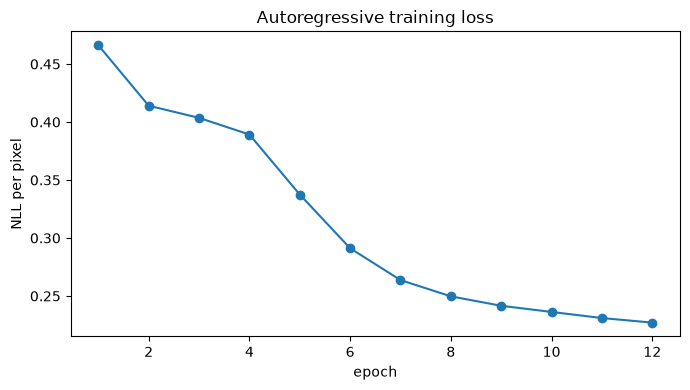

In [11]:
fig, axis = plt.subplots(figsize=(7, 4))
axis.plot(np.arange(1, len(training_history) + 1), training_history, marker="o")
axis.set(title="Autoregressive training loss", xlabel="epoch", ylabel="NLL per pixel")
plt.tight_layout()
plt.show()

## 8. Evaluate exact likelihood

The model assigns a conditional probability to the observed value of every pixel. For one image flattened into $x_1,\ldots,x_T$, its joint probability is the product

$$
p(x_1,\ldots,x_T)=p(x_1)\prod_{t=2}^{T}p(x_t\mid x_1,\ldots,x_{t-1}).
$$

Teacher-forcing inputs let us obtain all of these conditional distributions in one forward pass. At each position, cross-entropy selects the probability assigned to the pixel that actually occurred and takes its negative logarithm. Summing the token losses therefore gives the image NLL:

$$
\mathrm{NLL}(x)=-\log p(x)=-\sum_{t=1}^{T}\log p(x_t\mid x_{<t}).
$$

For example, suppose a three-pixel image is `[1, 0, 1]` and the model assigns the observed values probabilities `[0.8, 0.6, 0.5]`. The image probability is $0.8\times0.6\times0.5=0.24$, and its NLL is $-\log(0.24)$. We do not need to enumerate all $2^T$ possible images; we only evaluate the chain of conditionals for the image in front of us.

The likelihood is called **exact** because softmax gives a normalized probability over the two possible values at every position, and the autoregressive factorization gives a normalized probability for the complete image. We can compute its log-likelihood directly, without an approximation such as a variational lower bound planned to be observed deeper in next notebooks.

The evaluation function accumulates summed NLL across all batches and divides by the total number of pixels. This produces average NLL per pixel, making results comparable across datasets or image sizes. Because PyTorch uses natural logarithms, its unit is **nats per pixel**. Dividing by $\log 2$ converts it to **bits per pixel**:

$$
\mathrm{bits\ per\ pixel}=\frac{\mathrm{total\ NLL}}{\mathrm{number\ of\ pixels}\times\log 2}
=\frac{\mathrm{NLL\ per\ pixel}}{\log 2}.
$$


In [12]:
@torch.no_grad()
def evaluate_autoregressive_model(model, sequences, batch_size=256):
    model.eval()
    loader = DataLoader(TensorDataset(sequences), batch_size=batch_size)
    total_nll = 0.0
    total_tokens = 0
    for (targets,) in loader:
        targets = targets.to(DEVICE)
        inputs = make_autoregressive_inputs(targets)
        logits, _ = model(inputs)
        batch_nll = autoregressive_cross_entropy(logits, targets, reduction="sum")
        total_nll += batch_nll.item()
        total_tokens += targets.numel()
    nll_per_pixel = total_nll / total_tokens
    bits_per_pixel = nll_per_pixel / math.log(2.0)
    return nll_per_pixel, bits_per_pixel


evaluation_nll, evaluation_bpp = evaluate_autoregressive_model(model, evaluation_sequences)
print(f"evaluation NLL/pixel: {evaluation_nll:.4f}")
print(f"evaluation bits/pixel: {evaluation_bpp:.4f}")

evaluation NLL/pixel: 0.2273
evaluation bits/pixel: 0.3280


A uniform binary predictor assigns probability $0.5$ to every pixel value and obtains exactly $1$ bit per pixel. The result above, about $0.328$ bits per pixel, is lower because the model has learned predictable structure in the synthetic images. Lower NLL or bits per pixel means greater probability assigned to the observed data, but it does not by itself guarantee that generated samples look better to humans.

## 9. Sequential ancestral sampling

Training uses all known targets at once, but generation starts with only BOS. At each step we:

1. predict the distribution for the next pixel;
2. sample zero or one from that distribution;
3. feed the sampled value back as the next input;
4. repeat until all 64 pixels have been generated.

### Exercise 7 — Implement ancestral sampling

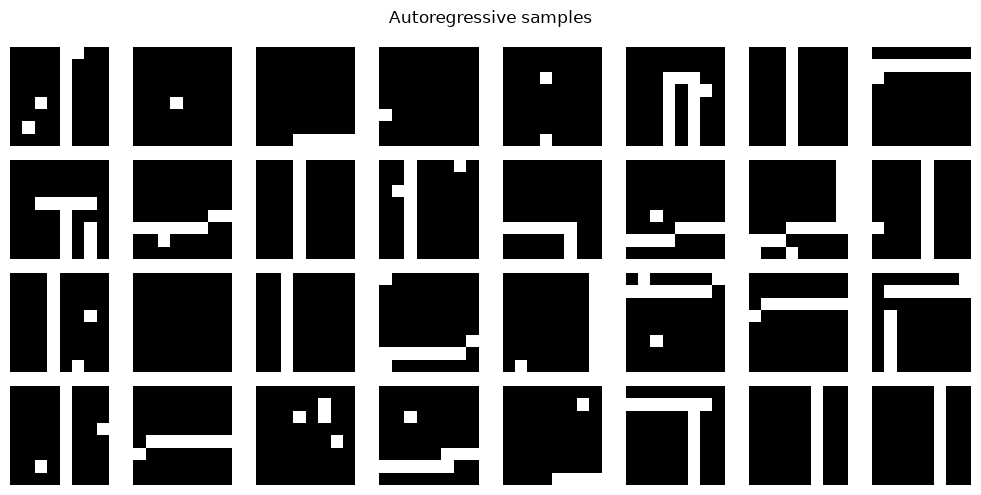

In [13]:
@torch.no_grad()
def sample_binary_images(model, number_images, image_size=8, temperature=1.0, seed=0):
    if temperature <= 0:
        raise ValueError("temperature must be positive")
    model.eval()
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    current_tokens = torch.full(
        (number_images, 1),
        BOS_TOKEN,
        dtype=torch.long,
        device=DEVICE,
    )
    hidden = None
    generated = []

    for _ in range(image_size * image_size):
        # run one recurrent step and select the single new-position logits.
        logits, hidden = model(current_tokens, hidden)
        logits = logits[:, -1, :]
        # apply temperature, convert to probabilities, and sample one pixel.
        next_tokens = torch.multinomial(
            F.softmax(logits / temperature, dim=-1),
            num_samples=1,
            generator=generator,
        )
        generated.append(next_tokens)
        current_tokens = next_tokens

    sequences = torch.cat(generated, dim=1).cpu()
    return sequences_to_images(sequences, image_size)


generated_images = sample_binary_images(model, 32, temperature=0.8, seed=SEED + 10)
assert generated_images.shape == (32, 8, 8)
assert set(generated_images.unique().tolist()) <= {0, 1}

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for axis, image in zip(axes.flat, generated_images):
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    axis.axis("off")
plt.suptitle("Autoregressive samples")
plt.tight_layout()
plt.show()

Although every image starts with the same BOS token, each row independently samples its first pixel from the same predicted distribution. Some rows can therefore draw zero while others draw one. Those different sampled values are fed back as the next inputs, producing different hidden states and probability distributions at later steps, so the images continue to diverge. The random seed makes the complete set reproducible; replacing sampling with `argmax` would normally keep identical starting sequences identical.

### Temperature

Before softmax, sampling divides logits by temperature. Lower temperature sharpens the distribution and makes common choices more likely; higher temperature increases diversity and mistakes. Temperature changes the sampling procedure, not the likelihood learned during training.

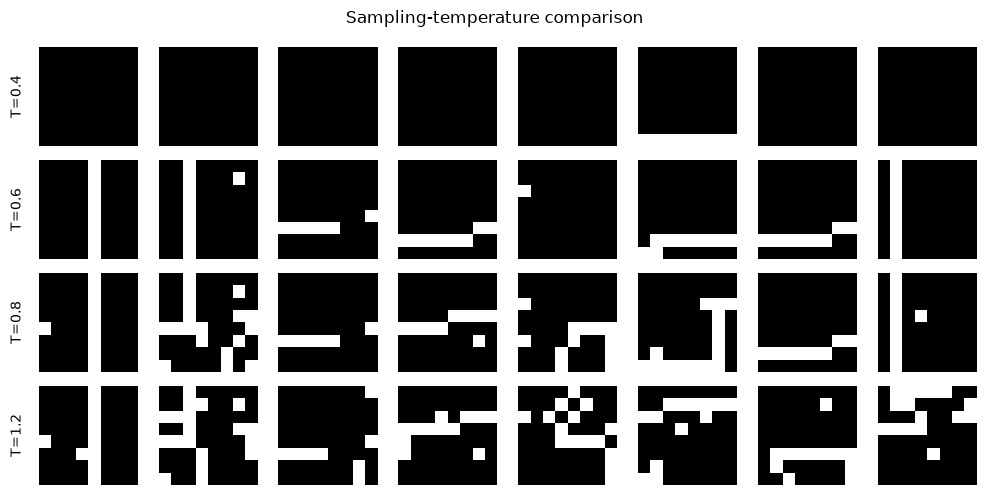

In [14]:
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for row, temperature in enumerate((0.4, 0.6, 0.8, 1.2)):
    samples = sample_binary_images(model, 8, temperature=temperature, seed=SEED + 20)
    for column, image in enumerate(samples):
        axes[row, column].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[row, column].axis("off")
    axes[row, 0].text(
        -0.15, 0.5, f"T={temperature}",
        transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right",
    )
plt.suptitle("Sampling-temperature comparison")
plt.tight_layout()
plt.show()

## 10. What this model can and cannot do

The model defines an explicit probability for every binary `8×8` image, including images unlike the training patterns. It can evaluate likelihood exactly and sample without an external decoder. However, it requires 64 sequential generation steps, and raster order gives earlier pixels a different role from later pixels.

For a large RGB image, individual-channel autoregression would require millions of steps. Practical systems therefore use parallel decoding approximations or generate shorter sequences of learned visual tokens.

## Reflection

1. Why does the probability chain rule let an autoregressive model represent a joint distribution?
2. Why is summed next-token cross-entropy equal to sequence NLL?
3. Why must training inputs be shifted relative to their targets?
4. What property of the GRU prevents information from future positions reaching earlier predictions?
5. Why can teacher-forced training process a complete sequence at once while generation cannot?
6. What does bits per pixel measure?
7. How does sampling temperature affect generated images?
8. Why is raster ordering an artificial inductive bias for images?
9. What makes likelihood exact for this model?
10. Why does exact likelihood not guarantee visually superior samples?

### Answers

1. The chain rule decomposes any joint probability into a product of conditional probabilities, each predicting one value from its preceding context.
2. Cross-entropy gives $-\log p(x_t\mid x_{<t})$ for each target; summing over positions gives $-\log p(x)$ by the chain rule.
3. Shifting ensures the model sees only earlier values and cannot copy the target it is currently predicting.
4. A forward GRU updates its hidden state from left to right, so an earlier output is computed before later inputs are processed.
5. Training already knows every previous target and can evaluate all shifted positions together; generation must first produce each value before using it as later context.
6. It is the average base-2 negative log-likelihood per modeled pixel value; lower values mean greater probability assigned to the data.
7. Lower temperature sharpens distributions and makes samples more predictable; higher temperature increases diversity and usually errors.
8. Images have no unique one-dimensional order, so raster order gives earlier and later pixels different roles chosen by us rather than by image structure.
9. Every conditional is a normalized softmax distribution, so their product gives a directly computable normalized probability for the image.
10. Likelihood rewards probability assigned to observed data, which is not the same criterion as human perceptual realism.